# OTT content investment model: walkthrough
Hypothetical case. Every input comes from `docs/assumptions_register.csv`; this notebook only calls the functions in `src/ott_model`.

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd
from ott_model import analysis as a, load_params, evaluate
from ott_model.params import load_register
pd.options.display.float_format = '{:,.2f}'.format

## 1. Assumptions

In [2]:
pd.DataFrame(load_register())[['id','unit','low','base','high','type']]

,id,unit,low,base,high,type
0,arpu_month,INR,45,70,110,ASSUMPTION
1,contribution_margin_sub,ratio,0.55,0.65,0.75,ASSUMPTION
2,monthly_churn,ratio,0.05,0.08,0.12,ASSUMPTION
3,existing_base_subs,subscribers,5000000,5000000,5000000,CASE_DEFINITION
4,discount_rate_annual,ratio,0.10,0.12,0.15,ASSUMPTION
5,horizon_months,months,36,36,36,CASE_DEFINITION
6,avod_cpm_inr,INR per 1000 impressions,90,180,300,ASSUMPTION
7,ad_impressions_per_hour,count,8,12,16,ASSUMPTION
8,ad_fill_rate,ratio,0.5,0.7,0.85,ASSUMPTION
9,ad_contribution_margin,ratio,0.8,0.8,0.8,ASSUMPTION


## 2. Scenario results (INR crore, PV at 12%)

In [3]:
st = a.scenario_table()
st.pivot(index='option', columns='scenario', values='npv_cr')[['downside','base','upside']]

scenario,downside,base,upside
option,,,
acquire,-3.65,-1.65,1.89
commission,-10.38,-3.30,7.01
coproduce,-4.68,0.65,9.09


In [4]:
st[st.scenario=='base'].set_index('option')[['pv_cost_cr','pv_sub_acquisition_cr','pv_sub_retention_cr','pv_advertising_cr','pv_secondary_licensing_cr','pv_residual_rights_cr','npv_cr','payback_month_from_launch']].T

option,commission,acquire,coproduce
pv_cost_cr,13.70,5.26,7.93
pv_sub_acquisition_cr,7.90,3.23,7.24
pv_sub_retention_cr,0.59,0.24,0.54
pv_advertising_cr,0.32,0.14,0.32
pv_secondary_licensing_cr,1.02,0.00,0.31
pv_residual_rights_cr,0.58,0.00,0.17
npv_cr,-3.30,-1.65,0.65
payback_month_from_launch,NaN,NaN,17.00


## 3. Break-even and indifference points

In [5]:
be = a.breakeven_table(); be[be.scenario=='base']

,scenario,option,parameter,current_value,breakeven_value,breakeven_over_current,current_effective_adds,breakeven_effective_adds
0,base,commission,gross_adds,"180,000.00","255,316.89",1.42,"180,000.00","255,316.89"
1,base,commission,arpu_month,70.00,97.17,1.39,NaN,NaN
2,base,commission,prod_cost_per_episode_cr,1.50,1.06,0.71,NaN,NaN
3,base,commission,monthly_churn,0.08,0.05,0.62,NaN,NaN
4,base,commission,avod_viewers,"1,500,000.00","27,643,485.67",18.43,NaN,NaN
5,base,acquire,gross_adds,"180,000.00","272,171.59",1.51,"72,000.00","108,868.64"
6,base,acquire,arpu_month,70.00,103.26,1.48,NaN,NaN
7,base,acquire,prod_cost_per_episode_cr,1.50,0.99,0.66,NaN,NaN
8,base,acquire,licence_fee_pct_of_prod_cost,0.45,0.30,0.66,NaN,NaN
9,base,acquire,monthly_churn,0.08,0.04,0.44,NaN,NaN


In [6]:
a.indifference_table()

,option_a,option_b,parameter,base_value,indifference_value,a_better_when
0,commission,coproduce,residual_rights_value_pct,0.10,1.08,above
1,commission,coproduce,post_window_factor,0.50,NaN,None
2,commission,coproduce,platform_cost_share,0.50,0.92,above
3,commission,coproduce,title_performance,1.00,3.16,above
4,commission,acquire,title_performance,1.00,1.25,above
5,coproduce,acquire,title_performance,1.00,0.53,above
6,coproduce,acquire,acq_audience_multiplier,0.40,0.66,below
7,commission,acquire,licence_fee_pct_of_prod_cost,0.45,0.60,above


## 4. Sensitivity

In [7]:
a.tornado().groupby('option').head(6)[['option','parameter','npv_at_low_cr','npv_at_high_cr','swing_cr']]

,option,parameter,npv_at_low_cr,npv_at_high_cr,swing_cr
27,acquire,prod_cost_per_episode_cr,1.24,-6.46,7.70
29,acquire,gross_adds,-3.79,3.18,6.97
33,acquire,licence_fee_pct_of_prod_cost,-0.04,-4.32,4.28
19,acquire,arpu_month,-2.89,0.33,3.22
34,acquire,acq_audience_multiplier,-2.97,0.11,3.08
21,acquire,monthly_churn,-0.65,-2.52,1.87
8,commission,prod_cost_per_episode_cr,3.46,-14.56,18.02
13,commission,gross_adds,-8.55,8.52,17.07
0,commission,arpu_month,-6.33,1.56,7.88
2,commission,monthly_churn,-0.06,-5.74,5.67


## 5. Monte Carlo
Triangular input distributions and a mean-one lognormal title-performance multiplier (assumptions; see `docs/methodology.md`).

In [8]:
mc = a.monte_carlo(n=20000, seed=7)
a.mc_summary(mc).set_index('option').T

option,commission,acquire,coproduce
mean_npv_cr,-4.20,-2.38,0.09
median_npv_cr,-6.28,-2.39,-1.87
sd_npv_cr,11.26,2.72,8.69
p05_npv_cr,-17.01,-6.85,-9.00
p25_npv_cr,-10.86,-4.16,-5.07
p75_npv_cr,-0.29,-0.69,2.86
p95_npv_cr,15.37,2.05,15.41
prob_npv_positive,0.24,0.17,0.38
cvar05_npv_cr,-19.33,-7.98,-10.49
prob_best_option,0.05,0.47,0.48


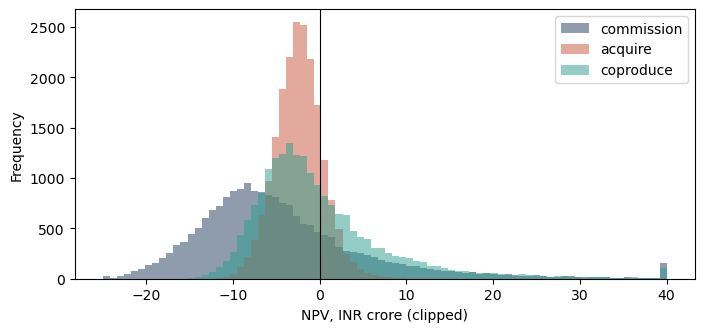

In [9]:
import matplotlib.pyplot as plt
ax = mc[['commission','acquire','coproduce']].clip(-25,40).plot.hist(bins=80, alpha=0.5, figsize=(8,3.5), color=['#1F3A5F','#C8553D','#2A9D8F'])
ax.axvline(0, color='k', lw=0.8); ax.set_xlabel('NPV, INR crore (clipped)');